No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


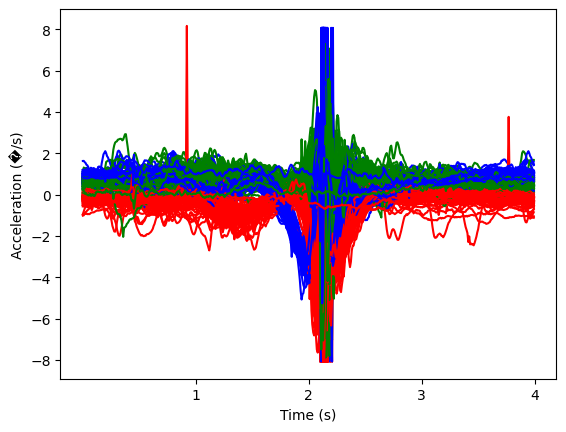

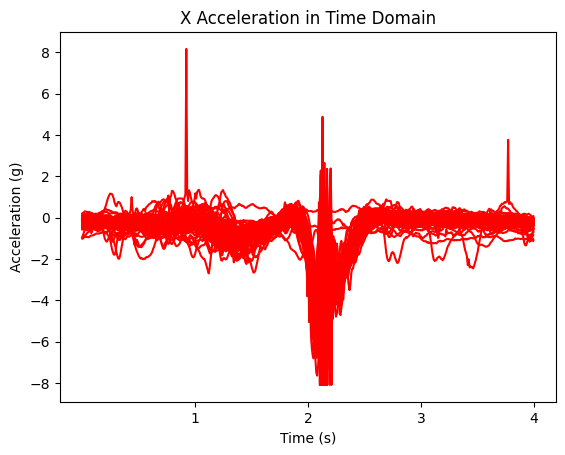

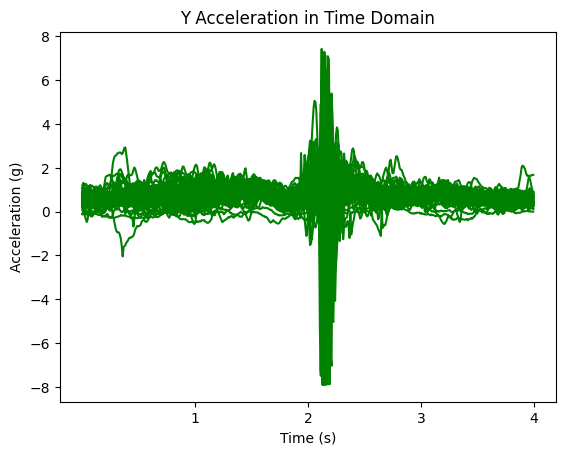

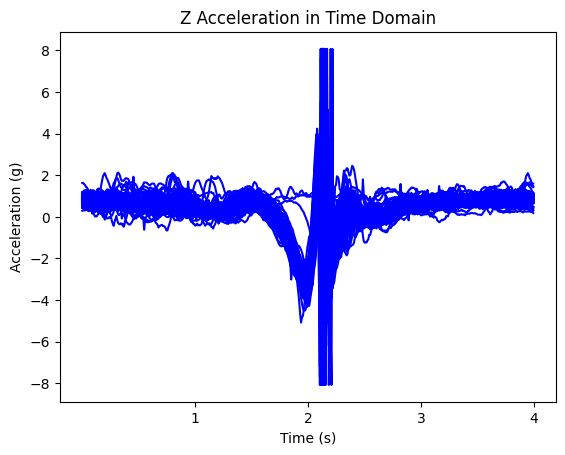

In [3]:
import numpy as np
from scipy.signal import find_peaks
import numpy as np
import matplotlib.pyplot as plt


def segment_Accel(bData):
#Convert CSV file to pandas then numpy array
    bData = np.genfromtxt(bData, delimiter=',', skip_header=1)
    bPacketNumber = bData[:, 0]
    f= 128 # because the frequency used is 128Hz
    bTimedomain = bPacketNumber / f   # because the frequency used is 128Hz
    bGyroX = bData[:, 1]
    bGyroY = bData[:, 2]
    bGyroZ = bData[:, 3]
    bAccelerationX = bData[:, 4]
    bAccelerationY = bData[:, 5]
    bAccelerationZ = bData[:, 6]

    bPacketNumber = bData[:, 0]
    bTimedomain = bPacketNumber / 128  # because the frequency used is 128Hz
    bGyroX = bData[:, 1]
    bGyroY = bData[:, 2]
    bGyroZ = bData[:, 3]
    bAccelerationX = bData[:, 4]
    bAccelerationY = bData[:, 5]
    bAccelerationZ = bData[:, 6]

    # Absolute magnitude of gyro data and curve smoothing
    bGyroMean = np.sqrt((bGyroX**2) + (bGyroY**2) + (bGyroZ**2))  # absolute magnitude backhand
    windowSize = 40
    bGyroMeanMovav = np.convolve(bGyroMean, np.ones(windowSize), 'valid') / windowSize  # moving average backhand
    bpks, _ = find_peaks(bGyroMeanMovav, prominence=200, distance=252, height=300)  # peak distance of 2s and min peak height of 300

    # Saving each shot into separate column of one big array
    # shot length is assumed to be 5s in length
    SignalTime = np.zeros((504, len(bpks)))
    SignalX = np.zeros((504, len(bpks)))
    SignalY = np.zeros((504, len(bpks)))
    SignalZ = np.zeros((504, len(bpks)))

    for j in range(len(bpks)):
        timeIndex = bpks[j]  # select first time value of peak
        startSignal = timeIndex - 252  # subtract 2s worth of data points from peak to obtain time when shot begins
        endSignal = timeIndex + 252  # add 2s worth of data points from peak to obtain end of signal
        if j == 0:
            startSignal = 0
            endSignal = 504
        elif j == len(bpks) - 1:
            startSignal = len(bTimedomain) - 504
            endSignal = len(bTimedomain)

        SignalTime[:, j] = bTimedomain[startSignal:endSignal]  # 1 shot in time index to be saved in Signal matrix
        SignalX[:, j] = bAccelerationX[startSignal:endSignal]
        SignalY[:, j] = bAccelerationY[startSignal:endSignal]
        SignalZ[:, j] = bAccelerationZ[startSignal:endSignal]
    plt.figure()
    for plotIdx in range(SignalX.shape[1]):
        plt.plot(SignalX[:, plotIdx], 'r')  # overlay all forehand shots onto 1 curve
        plt.plot(SignalY[:, plotIdx], 'g')  # overlay all forehand shots onto 1 curve
        plt.plot(SignalZ[:, plotIdx], 'b')  # overlay all forehand shots onto 1 curve
        plt.legend(['a_x', 'a_y', 'a_z'])
    plt.xlabel('Time (s)')  # x-axis label
    plt.ylabel('Acceleration (�/s)')  # y-axis label
    plt.legend().set_visible(False)

    # Uncomment the following lines if you want to plot the data
    plt.figure()
    for plotIdx in range(SignalX.shape[1]):
        plt.plot(SignalX[:, plotIdx], 'r')  # overlay all forehand shots onto 1 curve
        plt.xlabel('Time (s)')  # x-axis label
        plt.ylabel('Acceleration (g)')  # y-axis label
        plt.title('X Acceleration in Time Domain')
    plt.figure()
    for plotIdx in range(SignalX.shape[1]):
        plt.plot(SignalY[:, plotIdx], 'g')  # overlay all forehand shots onto 1 curve
        plt.xlabel('Time (s)')  # x-axis label
        plt.ylabel('Acceleration (g)')  # y-axis label
        plt.title('Y Acceleration in Time Domain')
    plt.figure()
    for plotIdx in range(SignalX.shape[1]):
        plt.plot(SignalZ[:, plotIdx], 'b')  # overlay all forehand shots onto 1 curve
        plt.xlabel('Time (s)')  # x-axis label

        plt.ylabel('Acceleration (g)')  # y-axis label
        plt.title('Z Acceleration in Time Domain')

    return SignalTime, SignalX, SignalY, SignalZ

In [1]:

bData='/Users/wisdomokoro/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/00992_CalInertialAndMag.csv'